# Sentiment Analysis of Patient Drug Reviews
**Oasis Infobyte SIP | Data Analytics | Level 1 - Task 4**

Dataset: UCI Drug Review Dataset (Drugs.com), https://archive.ics.uci.edu/dataset/462/drug+review+dataset+drugs+com

In [1]:
import re, string, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_style("whitegrid")

In [2]:
raw = pd.read_csv("drugsComTrain_raw.csv")
print("Raw shape:", raw.shape)

df = raw[["review", "rating"]].dropna().copy()
df["review"] = df["review"].apply(html.unescape).str.strip().str.strip('"').str.strip()

before = len(df)
df = df.drop_duplicates(subset="review")
print("Duplicates removed:", before - len(df))

def to_sentiment(r):
    if r >= 7: return "Positive"
    if r <= 4: return "Negative"
    return "Neutral"
df["sentiment"] = df["rating"].apply(to_sentiment)

# stratified 40k sample for speed (class ratio stays the same)
df, _ = train_test_split(df, train_size=40000, stratify=df["sentiment"], random_state=42)
df = df.reset_index(drop=True)

print(df["sentiment"].value_counts())
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

Raw shape: (161297, 7)
Duplicates removed: 48980
sentiment
Positive    26527
Negative     9914
Neutral      3559
Name: count, dtype: int64
sentiment
Positive    66.32
Negative    24.78
Neutral      8.90
Name: proportion, dtype: float64


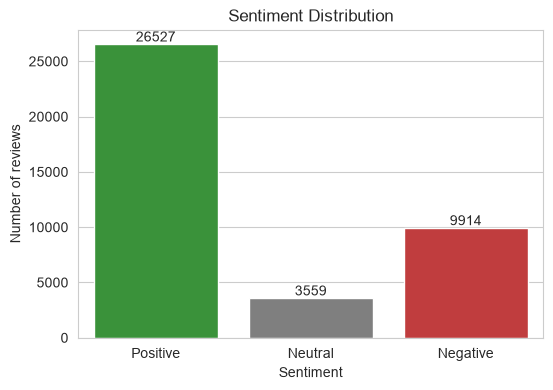

In [3]:
order = ["Positive", "Neutral", "Negative"]

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="sentiment", hue="sentiment", order=order, hue_order=order,
                   palette=["#2ca02c", "#7f7f7f", "#d62728"], legend=False)

for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

**Observation:** The dataset is imbalanced. Positive reviews are the majority (26,527 reviews, 66.3%), followed by Negative (9,914, 24.8%) and Neutral (3,559, 8.9%). Because Neutral is so small, a model can get high accuracy by mostly predicting Positive, so Macro F1 and per-class recall are more reliable than accuracy here. The labels are derived from the star rating (7-10 Positive, 5-6 Neutral, 1-4 Negative), not manually annotated.

## Text Preprocessing
Steps applied to each review:
1. HTML codes fixed (&#039; -> ') and duplicate reviews removed
2. Converted to lowercase
3. "n't" expanded to " not" (e.g. didn't -> did not) so negation is not lost
4. URLs, punctuation and numbers removed
5. Tokenisation (split text into words)
6. Stopwords removed (the, is, me...). I kept "not", "no", "nor" because they change the meaning of a sentence ("not good" is negative)
7. Lemmatization (running -> run, side effects -> side effect) to reduce word variations

In [4]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

for pkg in ["stopwords", "punkt", "punkt_tab", "wordnet"]:
    nltk.download(pkg, quiet=True)

In [5]:
#  keep negation words: "not good" must not become "good"
stop_words = set(stopwords.words("english")) - {"not", "no", "nor"}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"n't\b", " not", text)                 # didn't -> did not
    text = re.sub(r"http\S+|www\S+", " ", text)           # URLs
    text = re.sub(r"[%s]" % re.escape(string.punctuation), " ", text)
    text = re.sub(r"\d+", " ", text)                      # numbers
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and (len(t) > 2 or t == "no")]
    return " ".join(tokens)

# test 
sample = "I didn't like it. It made me dizzy & the pain got WORSE!!"
print(clean_text(sample))

not like made dizzy pain got worse


In [6]:
df["clean"] = df["review"].apply(clean_text)
df = df[df["clean"].str.strip() != ""].reset_index(drop=True)
df[["review", "clean"]].iloc[[0, 1, 4]]

,review,clean
0,"My 2 year old had a bad cough, sinus infection...",year old bad cough sinus infection could not g...
1,My doctor added 1 mg Abilify to my Wellbutrin ...,doctor added abilify wellbutrin name brand not...
4,Daily diarrhea for 50 years. Recently diagnos...,daily diarrhea year recently diagnosed ulcerat...


In [7]:
for i in [0, 1, 4]:
    print("BEFORE:", df["review"][i][:200])
    print("AFTER :", df["clean"][i][:200])
    print()

BEFORE: My 2 year old had a bad cough, sinus infection, we just couldn't get it to clear up, the Doctor gave us a sample. Loved it.
AFTER : year old bad cough sinus infection could not get clear doctor gave sample loved

BEFORE: My doctor added 1 mg Abilify to my Wellbutrin (Name Brand, not generic).  About two weeks later, a huge difference in the way that I feel.  I have struggled with depression for many years.  This episo
AFTER : doctor added abilify wellbutrin name brand not generic two week later huge difference way feel struggled depression many year episode started march extremely stubborn tried lexapro six week pristiq si

BEFORE: Daily diarrhea for 50 years. Recently  diagnosed ulcerative colitis   Asacol for 10 days only.  Diarrhea gone. Gone! In my 70's and just starting to live--thanks to Asacol.
AFTER : daily diarrhea year recently diagnosed ulcerative colitis asacol day diarrhea gone gone starting live thanks asacol



## TF-IDF Feature Extraction
TF-IDF (Term Frequency - Inverse Document Frequency) gives each word a weight.
- TF = how often a word appears in one review.
- IDF = how rare the word is across all reviews.

Words that appear often in one review but rarely in others (e.g. "dizzy", "worked", "nausea") get a high score, because they help separate positive and negative reviews. Common words get a low score. This is better than raw word counts.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["sentiment"],
    test_size=0.2, random_state=42, stratify=df["sentiment"])

test_idx = X_test.index   # needed later for error analysis

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)   # fit only on training data to avoid data leakage
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

(31998, 10000) (8000, 10000)


## Model Training
1. Multinomial Naive Bayes: fast baseline, works well with TF-IDF text.
2. Logistic Regression: linear model, usually stronger on text. I used class_weight="balanced" because the Neutral class is small (~9%), so the model gives it more importance.

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_tfidf, y_train)

models = {"Naive Bayes": nb, "Logistic Regression": lr}
preds = {name: m.predict(X_test_tfidf) for name, m in models.items()}
print("Both models trained")

Both models trained


Naive Bayes
              precision    recall  f1-score   support

    Negative      0.748     0.417     0.535      1983
     Neutral      0.000     0.000     0.000       712
    Positive      0.749     0.974     0.847      5305

    accuracy                          0.749      8000
   macro avg      0.499     0.463     0.461      8000
weighted avg      0.682     0.749     0.694      8000

Logistic Regression
              precision    recall  f1-score   support

    Negative      0.633     0.690     0.661      1983
     Neutral      0.185     0.364     0.245       712
    Positive      0.898     0.751     0.818      5305

    accuracy                          0.702      8000
   macro avg      0.572     0.602     0.575      8000
weighted avg      0.769     0.702     0.728      8000



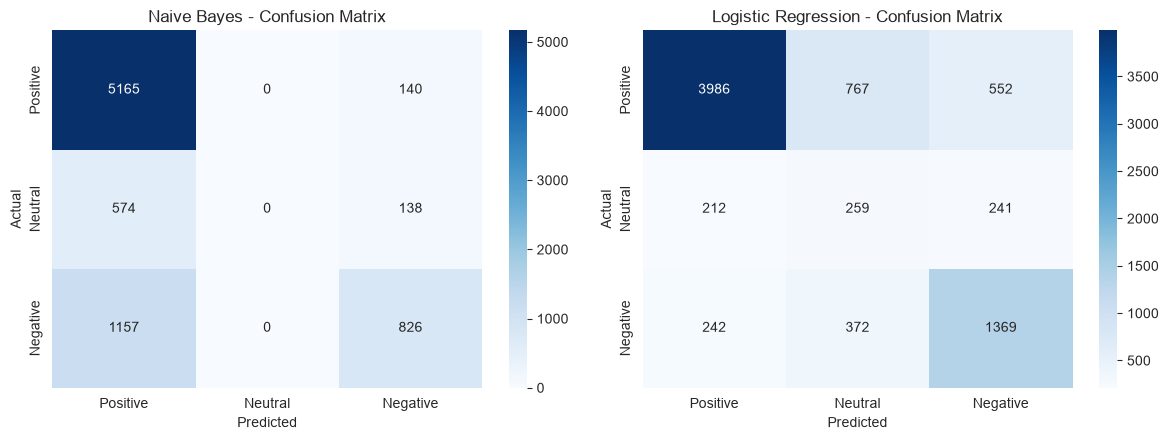

In [10]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

labels = ["Positive", "Neutral", "Negative"]
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, y_pred) in zip(axes, preds.items()):
    acc = accuracy_score(y_test, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    fm = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)[2]
    rows.append([name, acc, p, r, f, fm])

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [11]:
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "Macro F1"]).round(4)
results

,Model,Accuracy,Precision,Recall,F1,Macro F1
0,Naive Bayes,0.7489,0.6821,0.7489,0.6941,0.4606
1,Logistic Regression,0.7018,0.7688,0.7018,0.7281,0.5747


## Model Evaluation - Observations

| Model | Accuracy | Weighted F1 | Macro F1 | Neutral Recall |
|---|---|---|---|---|
| Naive Bayes | 0.749 | 0.694 | 0.461 | 0.000 |
| Logistic Regression | 0.702 | 0.728 | 0.575 | 0.364 |

**1. Accuracy vs Macro F1:**
Naive Bayes has the higher accuracy (74.9% vs 70.2%), but this is misleading. The data is imbalanced (Positive ~66%, Negative ~25%, Neutral ~9%), so a model that mostly predicts Positive gets high accuracy. Naive Bayes has a Positive recall of 0.974 but a Negative recall of only 0.417. Logistic Regression has a much better Macro F1 (0.575 vs 0.461), which treats all three classes equally, so it is the better model overall.

**2. Neutral class:**
Naive Bayes never predicted the Neutral class (precision, recall and F1 are all 0.000). The Multinomial Naive Bayes model learns class priors from the data, so with only ~9% Neutral reviews it always chooses Positive or Negative. Logistic Regression with class_weight="balanced" gets a Neutral recall of 0.364, but its precision is only 0.185, which means many reviews predicted as Neutral are actually Positive or Negative. Neutral is the hardest class because reviews with rating 5-6 usually contain both positive and negative words.

**3. Confusion matrix:**
Most mistakes happen between Positive and Neutral (767 Positive reviews were predicted as Neutral and 212 Neutral reviews as Positive). For Logistic Regression, 212 Neutral reviews were predicted as Positive and 241 as Negative.

**4. Trade-off:**
Class weighting improved Negative recall (0.417 -> 0.690) and Neutral recall (0 -> 0.364), but reduced Positive recall (0.974 -> 0.751) and overall accuracy. Which model is better depends on the goal. For finding negative feedback and side-effect complaints, Logistic Regression is more useful because it misses fewer negative reviews.

**5. Label limitation:**
Labels come from the star rating, not manual annotation. A user can give a rating of 6 and still write a very positive review, so some errors are label noise rather than model failure.

In [12]:
# !pip install wordcloud  (run once if wordcloud is not installed)

Removed from clouds: ['also', 'back', 'bad', 'day', 'doctor', 'effect', 'feel', 'first', 'get', 'got', 'like', 'medication', 'month', 'no', 'not', 'one', 'pain', 'period', 'pill', 'side', 'started', 'take', 'taking', 'time', 'took', 'week', 'weight', 'work', 'would', 'year']


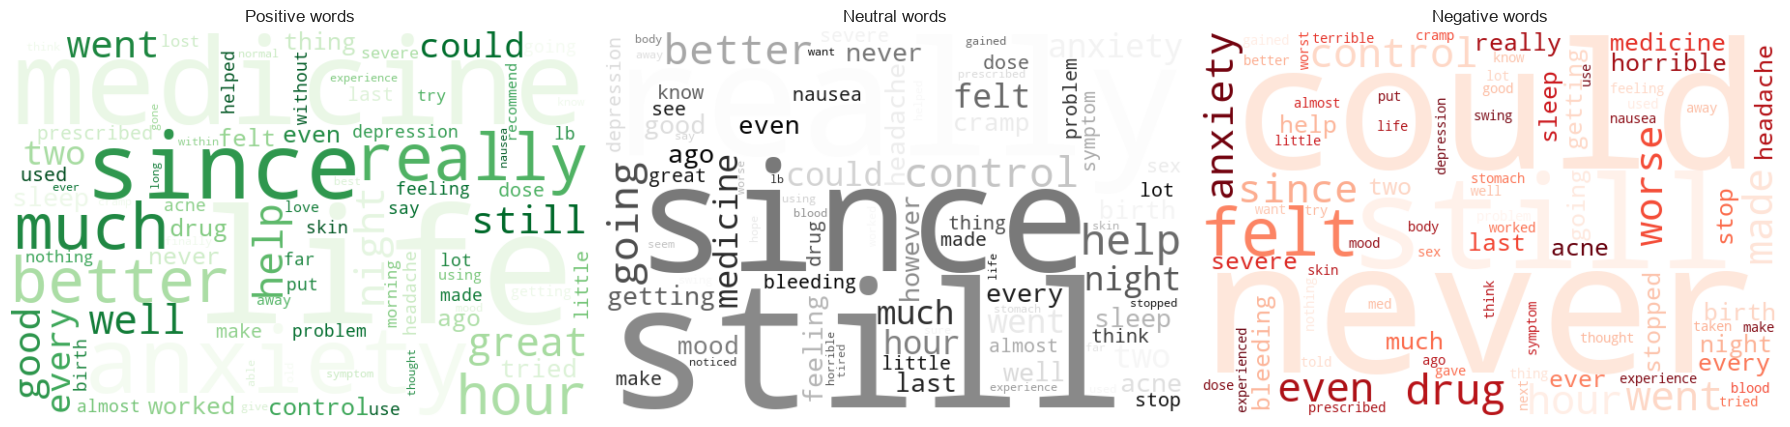

In [13]:
from collections import Counter
from wordcloud import WordCloud

classes = ["Positive", "Neutral", "Negative"]

# top 40 words in each class
top = {}
for s in classes:
    words = " ".join(df.loc[df["sentiment"] == s, "clean"]).split()
    top[s] = {w for w, _ in Counter(words).most_common(40)}

# words that appear in the top 40 of all three classes
common_words = top["Positive"] & top["Neutral"] & top["Negative"]
print("Removed from clouds:", sorted(common_words))

colors = {"Positive": "Greens", "Neutral": "Greys", "Negative": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, classes):
    text = " ".join(df.loc[df["sentiment"] == s, "clean"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap=colors[s], max_words=80,
                   stopwords=common_words, collocations=False,
                   random_state=42).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{s} words")

plt.tight_layout()
plt.show()

## WordCloud Observations

- **Positive:** Words like "better", "well", "good", "great", "helped", "worked", "love" and "recommend" stand out. These show that the medicine worked and improved the patient's condition.
- **Negative:** Words like "never", "worse", "stop", "stopped", "horrible", "terrible", "severe", "headache", "bleeding" and "anxiety" stand out. These show side effects, bad experiences and patients stopping the medicine. "could" and "never" are probably from phrases like "could not" and "never again".
- **Neutral:** Contains a mix of positive words ("better", "good", "great", "help") and negative words ("bleeding", "nausea", "cramp"), along with words like "still", "going" and "getting" that describe an ongoing experience. This mixed vocabulary is why Neutral is the hardest class (low recall in both models).
- Some generic words such as "since", "still", "much", "really" and "could" appear large in all three clouds, so they carry little sentiment information on their own.
- "anxiety" is most prominent in the Negative cloud, but it also appears in the others because it is a medical condition people write about, not only a sentiment word.
- Words common to all three classes ("side", "effect", "not", "pill", "pain", "period") were removed from the clouds only for visualisation. The models still use them.

In [14]:
best_name = "Logistic Regression"
best_pred = preds[best_name]

err = pd.DataFrame({
    "review": df.loc[test_idx, "review"].values,
    "rating": df.loc[test_idx, "rating"].values,
    "actual": y_test.values,
    "predicted": best_pred,
})
err = err[err["actual"] != err["predicted"]]

print(f"Misclassified: {len(err)} of {len(y_test)} ({len(err)/len(y_test)*100:.1f}%)")
print()
print(err.groupby(["actual", "predicted"]).size().sort_values(ascending=False))

Misclassified: 2386 of 8000 (29.8%)

actual    predicted
Positive  Neutral      767
          Negative     552
Negative  Neutral      372
          Positive     242
Neutral   Negative     241
          Positive     212
dtype: int64


In [15]:
pd.set_option("display.max_colwidth", 400)

# pick one example from each error type (actual -> predicted), then choose 5 of them
per_type = err.groupby(["actual", "predicted"]).sample(1, random_state=7)
samples = per_type.sample(min(5, len(per_type)), random_state=7).reset_index(drop=True)

for i, row in samples.iterrows():
    print(f"Example {i+1} | rating={row['rating']} | actual={row['actual']} | predicted={row['predicted']}")
    print(row["review"][:400])
    print("-" * 80)

Example 1 | rating=5 | actual=Neutral | predicted=Positive
I am on day 2 of this antibiotic for a severe sinus infection. On my first dose of the 2 pills, my stomach started becoming upset, it was bloating and overall bad feeling in my gut. Day 2 (which is where I am at now), and I do feel much better concerning my sinus issues but my stomach still hurts and I am bloated. I have been taking this antibiotic for years and have not experienced this before wi
--------------------------------------------------------------------------------
Example 2 | rating=9 | actual=Positive | predicted=Neutral
I had extreme fatigue with back pain, headache and nausea for 3-4 weeks.  I couldn't sleep but was tired all the time.  After 2-3 days taking the 6 day Dosepak I felt 80% better.  I was still a little fatigued and my back still hurt some but I truly felt 80% better.  I am starting day 4 tomorrow and hope to continue on this path as life has been absolutely miserable the last few weeks.
-----------

## Error Analysis

Logistic Regression misclassified 2386 of 8000 test reviews (29.8%). The most common mistake was Positive predicted as Neutral (767 reviews), followed by Positive predicted as Negative (552). This is expected because Positive is the biggest class, so even a small error rate gives a large number of mistakes. Also, class_weight="balanced" pushes the model to predict Neutral more often. Of the 712 Neutral reviews, 453 were misclassified (241 as Negative, 212 as Positive).

**Example 1** (rating 5, actual: Neutral, predicted: Positive)
The patient writes "I feel much better concerning my sinus issues" but also "my stomach still hurts and I am bloated". It is mixed sentiment. Positive words probably outweighed the negative ones in the TF-IDF scores, so the model predicted Positive.

**Example 2** (rating 9, actual: Positive, predicted: Neutral)
The review describes the illness symptoms before treatment (extreme fatigue, back pain, headache, nausea, "life has been absolutely miserable"). These are negative words, but they describe the disease, not the drug. The model cannot tell the difference, so the negative words cancelled the positive part ("felt 80% better").

**Example 3** (rating 4, actual: Negative, predicted: Neutral)
The review talks about pain and a lot of blood, but also says "my doctor said it was normal". Rating 4 is also right at the border between Negative (1-4) and Neutral (5-6), so the label itself is borderline.

**Example 4** (rating 6, actual: Neutral, predicted: Negative)
The review is full of negative words (threw up, still going, enema), but the patient gave 6/10. The words look negative while the rating is in the middle, so this is probably label noise caused by rating-derived labels.

**Example 5** (rating 3, actual: Negative, predicted: Positive)
The patient praises the old drug ("really cleared my skin") and complains about the new one ("Trinessa is horrible in helping acne"). Positive words about the old drug were counted toward the whole review. The model cannot connect a sentiment to the correct drug.

**Common reasons for errors:**
1. **Mixed sentiment:** positive and negative words appear in the same review (Examples 1, 3).
2. **Symptom words vs side-effect words:** describing the illness looks negative to the model (Example 2).
3. **Rating-derived labels:** the rating does not always match the text, and ratings near 4/5 and 6/7 are borderline (Examples 3, 4).
4. **Multiple drugs in one review:** TF-IDF has no way to link a word to a specific drug (Example 5).
5. **Bag-of-words limit:** TF-IDF ignores word order and context, so it misses sarcasm and comparisons.

## Conclusion

- **Best model:** Logistic Regression (Macro F1 0.575, accuracy 0.702). Naive Bayes had higher accuracy (0.749) but a Macro F1 of only 0.461 because it never predicted the Neutral class.
- **Why:** Logistic Regression with class_weight="balanced" handles the imbalanced classes better and detects more Negative reviews (recall 0.690 vs 0.417).
- **Limitations:** labels come from star ratings, Neutral is hard to separate (recall 0.364, precision 0.185), and TF-IDF cannot understand context, negation in long sentences or multiple drugs in one review.
- **Real-world uses:** finding side-effect complaints early, monitoring patient opinion about drugs, and helping pharma and healthcare companies analyse patient feedback at scale.
- **Future work:** try ComplementNB or SVM, use sentence embeddings or BERT, and use manually labelled data for the Neutral class.